Algoritmo Determinístico

Nessa seção o código pretende ver sobre o uso do Qlearning e Sarsa no Taxi-v4 do Gymnasium


### Com o Qlearning

In [15]:
import random
from IPython.display import clear_output
import gymnasium as gym
import numpy as np
from numpy import loadtxt
import random

In [16]:
import numpy as np
import random
import matplotlib.pyplot as plt
from numpy import savetxt


class QLearning:
    def __init__(self, env, alpha, gamma, epsilon, epsilon_min, epsilon_dec, episodes):
        self.env = env
        self.q_table = np.zeros([env.observation_space.n, env.action_space.n])
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_dec = epsilon_dec
        self.episodes = episodes

        self.rewards_per_episode   = []
        self.timesteps_per_episode = []       

    def select_action(self, state):
        rv = random.uniform(0, 1)
        if rv < self.epsilon:
            return self.env.action_space.sample()
        return np.argmax(self.q_table[state])

    # timestepFile declarado na assinatura (default None)
    def train(self, filename=None, plotFile=None, rewardFile=None, timestepFile=None):
        for i in range(1, self.episodes + 1):
            (state, _) = self.env.reset()
            rewards   = 0
            done      = False
            timesteps = 0                       

            while not done:
                action = self.select_action(state)
                next_state, reward, done, _, _ = self.env.step(action)

                old_value = self.q_table[state, action]
                next_max  = np.max(self.q_table[next_state])
                new_value = old_value + self.alpha * (reward + self.gamma * next_max - old_value)
                self.q_table[state, action] = new_value

                state      = next_state
                timesteps += 1
                rewards   += reward

            self.timesteps_per_episode.append(timesteps)   
            self.rewards_per_episode.append(rewards)

            if i % 500 == 0:
                avg = np.mean(self.rewards_per_episode[-100:])
                print(f"Episódio: {i}/{self.episodes} | ε={self.epsilon:.4f} | "
                      f"reward médio (últimos 100): {avg:.2f}")

            if self.epsilon > self.epsilon_min:
                self.epsilon = self.epsilon * self.epsilon_dec

        if filename:
            savetxt(filename, self.q_table, delimiter=',')
        if plotFile is not None:
            self.plotactions(plotFile, self.timesteps_per_episode)
        if rewardFile is not None:
            self.plotrewards(rewardFile)
        if timestepFile is not None:                     
            self.plottimesteps(timestepFile)

        return self.q_table

    def plotactions(self, plotFile, actions_per_episode):
        plt.plot(actions_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Actions')
        plt.title('# Actions vs Episodes')
        plt.savefig(plotFile + ".jpg")
        plt.close()

    def plotrewards(self, rewardFile):
        plt.plot(self.rewards_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('Reward')
        plt.title('Reward vs Episodes')
        plt.savefig(rewardFile + ".jpg")
        plt.close()

    def plottimesteps(self, timestepFile):
        plt.plot(self.timesteps_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Timesteps')
        plt.title('# Timesteps vs Episodes')
        plt.savefig(timestepFile + ".jpg")
        plt.close()

In [17]:
import os

os.makedirs('data_qlearning', exist_ok=True)
os.makedirs('results_qlearning', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 10_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = gym.make("Taxi-v4", render_mode='ansi').env
    qlearning = QLearning(env, alpha=0.1, gamma=0.99,
                          epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                          episodes=EPISODES)

    qlearning.train(
        filename     = f'data_qlearning/q-table-taxi-driver-qlearning-run{run+1}.csv',
        plotFile     = f'results_qlearning/actions_qlearning_run{run+1}',
        rewardFile   = f'results_qlearning/rewards_qlearning_run{run+1}',
        timestepFile = f'results_qlearning/timesteps_qlearning_run{run+1}'
    )

    all_rewards.append(qlearning.rewards_per_episode)      # ← qlearning, não sarsa
    all_timesteps.append(qlearning.timesteps_per_episode)  # ← qlearning, não sarsa
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")
    
ql_rewards = np.array(all_rewards)
np.save('results_qlearning/rewards_qlearning.npy', ql_rewards)

Episódio: 500/10000 | ε=0.0498 | reward médio (últimos 100): -28.22
Episódio: 1000/10000 | ε=0.0498 | reward médio (últimos 100): -0.35
Episódio: 1500/10000 | ε=0.0498 | reward médio (últimos 100): 4.51
Episódio: 2000/10000 | ε=0.0498 | reward médio (últimos 100): 4.74
Episódio: 2500/10000 | ε=0.0498 | reward médio (últimos 100): 5.68
Episódio: 3000/10000 | ε=0.0498 | reward médio (últimos 100): 4.16
Episódio: 3500/10000 | ε=0.0498 | reward médio (últimos 100): 5.28
Episódio: 4000/10000 | ε=0.0498 | reward médio (últimos 100): 5.39
Episódio: 4500/10000 | ε=0.0498 | reward médio (últimos 100): 4.74
Episódio: 5000/10000 | ε=0.0498 | reward médio (últimos 100): 5.30
Episódio: 5500/10000 | ε=0.0498 | reward médio (últimos 100): 5.26
Episódio: 6000/10000 | ε=0.0498 | reward médio (últimos 100): 5.40
Episódio: 6500/10000 | ε=0.0498 | reward médio (últimos 100): 5.82
Episódio: 7000/10000 | ε=0.0498 | reward médio (últimos 100): 6.12
Episódio: 7500/10000 | ε=0.0498 | reward médio (últimos 100)

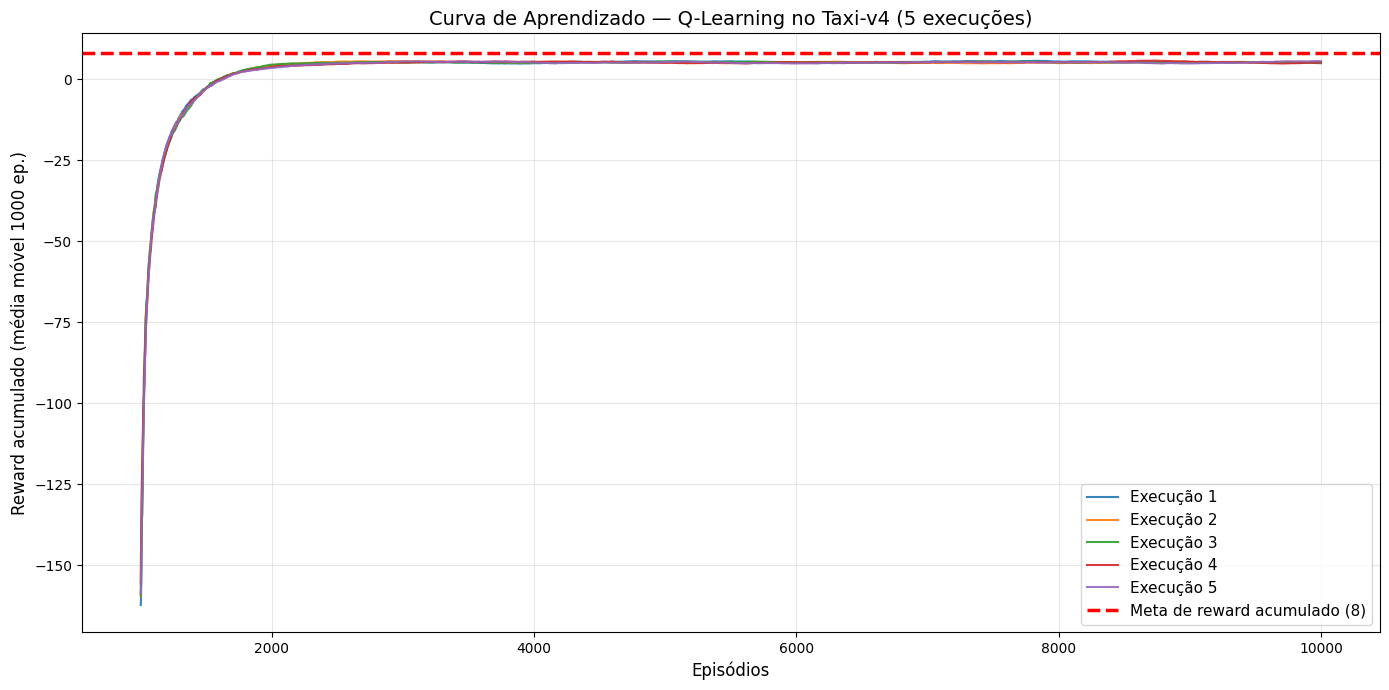

In [18]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-Learning no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_qlearning/learning_curve_5runs.jpg', dpi=120)
plt.show()

#### Discussão - Curva de aprendizado do Q-learning

O aprendizado aconteceu em três fases nas cinco execuções:

1. **Início (<500 episódios):** o agente não sabe nada e age aleatoriamente. Por isso que o reward fica muito negativo.
2. **Aprendizado (500-1500 episódios):** o reward sobe rápido e fica positivo entre episódio 1000 a 1500.
3. **Estabilidade (>2000 episódios):** o reward para de subir e fica em um estado estável mas menor do que a meta.

**Por que a curva não chega na meta?**

O agente ganha mais 20 ao entregar o passageiro e perde 1 ponto cada passo que der. Uma viagem ótima leva 13 passos, dando um reward de 8, a meta. Quando o agente é treindado, o agente faz algumas ações alteatórias para continuar explorando o mundo. Isso gera mais passos e mais penalidades, puxando o reward para baixo de 8.

In [19]:
N_EVAL = 100

for run in range(1, 6):
    q_table = np.loadtxt(f'data_qlearning/q-table-taxi-driver-qlearning-run{run}.csv', delimiter=',')

    env = gym.make("Taxi-v4", render_mode='ansi').env

    timesteps    = []
    rewards_eval = []
    penalties    = []

    for ep in range(N_EVAL):
        (state, _) = env.reset()
        done = False
        steps = 0
        ep_reward = 0
        pen = 0

        while not done and steps < 200:
            action = np.argmax(q_table[state])
            state, reward, done, _, _ = env.step(action)
            steps += 1
            ep_reward += reward
            if reward == -10:
                pen += 1

        timesteps.append(steps)
        rewards_eval.append(ep_reward)
        penalties.append(pen)

    env.close()

    timesteps = np.array(timesteps)
    print(f"Execução de número: {run}")
    print(f"Média de timesteps:{timesteps.mean():.2f}")
    print(f"Desvio padrão:{timesteps.std():.2f}")
    print(f"Mínimo / Máximo:{timesteps.min()} / {timesteps.max()}")
    print(f"Reward médio:{np.mean(rewards_eval):.2f}")
    print(f"Penalidades (média):{np.mean(penalties):.2f}")
    print("\n")

Execução de número: 1
Média de timesteps:13.35
Desvio padrão:2.73
Mínimo / Máximo:6 / 18
Reward médio:7.65
Penalidades (média):0.00


Execução de número: 2
Média de timesteps:12.79
Desvio padrão:2.78
Mínimo / Máximo:6 / 18
Reward médio:8.21
Penalidades (média):0.00


Execução de número: 3
Média de timesteps:12.81
Desvio padrão:2.86
Mínimo / Máximo:6 / 18
Reward médio:8.19
Penalidades (média):0.00


Execução de número: 4
Média de timesteps:13.27
Desvio padrão:2.64
Mínimo / Máximo:7 / 18
Reward médio:7.73
Penalidades (média):0.00


Execução de número: 5
Média de timesteps:12.60
Desvio padrão:2.75
Mínimo / Máximo:6 / 18
Reward médio:8.40
Penalidades (média):0.00




#### Discussão - Avaliação do agente (Q-learning)

Depois do treino, o agente foi executado 100 vezes usando só a Q-table, sem ações aleatórias:

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 13,35 | 2,73 | 6 / 18 | 7,65 | 0 |
| 2 | 12,79 | 2,78 | 6 / 18 | 8,21 | 0 |
| 3 | 12,81 | 2,86 | 6 / 18 | 8,19 | 0 |
| 4 | 13,27 | 2,64 | 7 / 18 | 7,73 | 0 |
| 5 | 12,60 | 2,75 | 6 / 18 | 8,40 | 0 |
| **Média** | **12,96** | **2,75** | — | **8,04** | **0** |

O agente completou a tarefa em todos os episódios, nunca errou um pickup ou dropoff e atingiu a meta de reward ~8. Isso mostra que ele conseguiu aprender de resolver o problema da melhor forma.

O desvio padrão de 2,49 passos não significa que o agente é inconsistente. Ele aconteceu porque cada episódio começa com o táxi, o passageiro e o destino em diversas posições diferentes. A quantidade de passos depende na distancia entre os três.

### Algoritmo SARSA

In [20]:
import sys

class Sarsa:

    def __init__(self, env, alpha, gamma, epsilon, epsilon_min, epsilon_dec, episodes):
        self.env = env
        self.q_table = np.zeros([env.observation_space.n, env.action_space.n])
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_dec = epsilon_dec
        self.episodes = episodes

        self.rewards_per_episode     = []
        self.timesteps_per_episode   = []     

    def select_action(self, state):
        rv = random.uniform(0, 1)
        if rv < self.epsilon:
            return self.env.action_space.sample()
        return np.argmax(self.q_table[state])

    def train(self, filename=None, plotFile=None, rewardFile=None, timestepFile=None):
        for i in range(1, self.episodes + 1):
            (state, _) = self.env.reset()
            a = self.select_action(state)
            rewards = 0
            done = False
            timesteps = 0                         

            while not done:
                next_state, reward, done, _, _ = self.env.step(a)

                old_value   = self.q_table[state, a]
                next_action = self.select_action(next_state)
                new_value   = old_value + self.alpha * (
                    reward + self.gamma * self.q_table[next_state, next_action] - old_value
                )
                self.q_table[state, a] = new_value

                state = next_state
                a = next_action
                timesteps += 1
                rewards   += reward

            self.timesteps_per_episode.append(timesteps)   
            self.rewards_per_episode.append(rewards)

            if i % 500 == 0:
                sys.stdout.write(f"Episódio: {i}/{self.episodes}\r")
                sys.stdout.flush()

            if self.epsilon > self.epsilon_min:
                self.epsilon = self.epsilon * self.epsilon_dec

        if filename:
            savetxt(filename, self.q_table, delimiter=',')
        if plotFile is not None:
            self.plotactions(plotFile, self.timesteps_per_episode)
        if rewardFile is not None:
            self.plotrewards(rewardFile)
        if timestepFile is not None:              
            self.plottimesteps(timestepFile)

        return self.q_table

    def plotactions(self, plotFile, actions_per_episode):
        plt.plot(actions_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Actions')
        plt.title('# Actions vs Episodes')
        plt.savefig(plotFile + ".jpg")
        plt.close()

    def plotrewards(self, rewardFile):
        plt.plot(self.rewards_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('Reward')
        plt.title('Reward vs Episodes')
        plt.savefig(rewardFile + ".jpg")
        plt.close()

    def plottimesteps(self, timestepFile):        
        
        plt.plot(self.timesteps_per_episode)
        plt.xlabel('Episodes')
        plt.ylabel('# Timesteps')
        plt.title('# Timesteps vs Episodes')
        plt.savefig(timestepFile + ".jpg")
        plt.close()

In [21]:
import os

os.makedirs('data_sarsa', exist_ok=True)
os.makedirs('results_sarsa', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 10_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = gym.make("Taxi-v4", render_mode='ansi').env
    sarsa = Sarsa(env, alpha=0.1, gamma=0.99,
                  epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                  episodes=EPISODES)

    sarsa.train(
        filename = f'data_sarsa/q-table-taxi-driver-sarsa-run{run+1}.csv',
        plotFile = f'results_sarsa/actions_sarsa_run{run+1}',
        rewardFile = f'results_sarsa/rewards_sarsa_run{run+1}',
        timestepFile = f'results_sarsa/timesteps_sarsa_run{run+1}' 
    )

    all_rewards.append(sarsa.rewards_per_episode)
    all_timesteps.append(sarsa.timesteps_per_episode)    
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")
    
sarsa_rewards = np.array(all_rewards)
np.save('results_sarsa/rewards_sarsa.npy', sarsa_rewards)

Timesteps por run (média final, últimos 1000 ep.):
  run1: 13.86
  run2: 13.76
  run3: 13.70
  run4: 13.80
  run5: 14.17


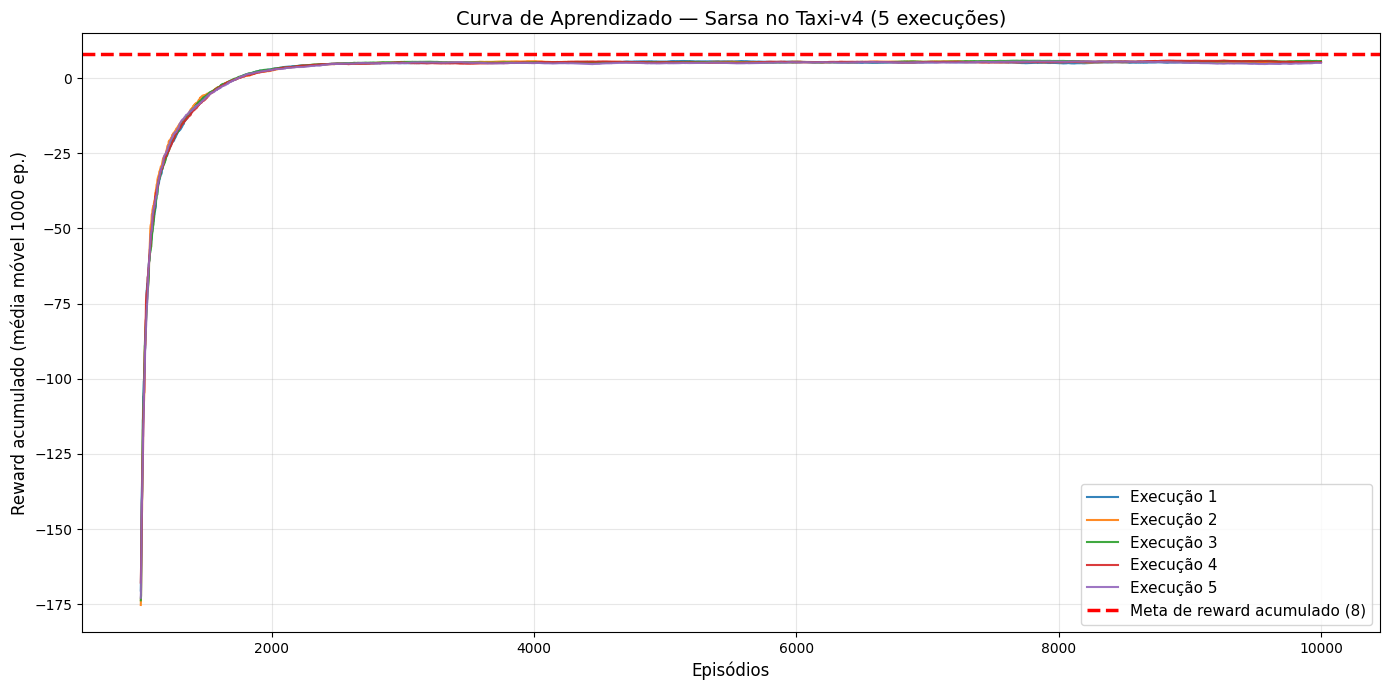

In [22]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Sarsa no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_sarsa/learning_curve_5runs.jpg', dpi=120)
plt.show()

In [23]:
N_EVAL = 100

for run in range(1, 6):
    q_table = np.loadtxt(f'data_sarsa/q-table-taxi-driver-sarsa-run{run}.csv', delimiter=',')

    env = gym.make("Taxi-v4", render_mode='ansi').env

    timesteps    = []
    rewards_eval = []
    penalties    = []

    for ep in range(N_EVAL):
        (state, _) = env.reset()
        done = False
        steps = 0
        ep_reward = 0
        pen = 0

        while not done and steps < 200:
            action = np.argmax(q_table[state])
            state, reward, done, _, _ = env.step(action)
            steps += 1
            ep_reward += reward
            if reward == -10:
                pen += 1

        timesteps.append(steps)
        rewards_eval.append(ep_reward)
        penalties.append(pen)

    env.close()

    timesteps = np.array(timesteps)
    print(f"Execução de número:{run}")
    print(f"Média de timesteps:{timesteps.mean():.2f}")
    print(f"Desvio padrão:{timesteps.std():.2f}")
    print(f"Mínimo / Máximo:{timesteps.min()} / {timesteps.max()}")
    print(f"Reward médio:{np.mean(rewards_eval):.2f}")
    print(f"Penalidades (média):{np.mean(penalties):.2f}")
    print("\n")

Execução de número:1
Média de timesteps:13.06
Desvio padrão:2.52
Mínimo / Máximo:6 / 18
Reward médio:7.94
Penalidades (média):0.00


Execução de número:2
Média de timesteps:12.94
Desvio padrão:3.00
Mínimo / Máximo:6 / 18
Reward médio:8.06
Penalidades (média):0.00


Execução de número:3
Média de timesteps:13.10
Desvio padrão:2.54
Mínimo / Máximo:7 / 18
Reward médio:7.90
Penalidades (média):0.00


Execução de número:4
Média de timesteps:12.53
Desvio padrão:2.71
Mínimo / Máximo:6 / 18
Reward médio:8.47
Penalidades (média):0.00


Execução de número:5
Média de timesteps:13.16
Desvio padrão:2.63
Mínimo / Máximo:6 / 18
Reward médio:7.84
Penalidades (média):0.00




#### Discussão - Resultados do Sarsa

Com os mesmos parâmetros do Q-learning, o Sarsa obteve:

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 13,06 | 2,52 | 6 / 18 | 7,94 | 0 |
| 2 | 12,94 | 3,00 | 6 / 18 | 8,06 | 0 |
| 3 | 13,10 | 2,54 | 7 / 18 | 7,90 | 0 |
| 4 | 12,53 | 2,71 | 6 / 18 | 8,47 | 0 |
| 5 | 13,16 | 2,63 | 6 / 18 | 7,84 | 0 |
| **Média** | **12,96** | **2,68** | — | **8,04** | **0** |

Assim como o Q-learning, o Sarsa completou todos os episódios, sem penalidades, e atingiu a meta de reward de ~8.

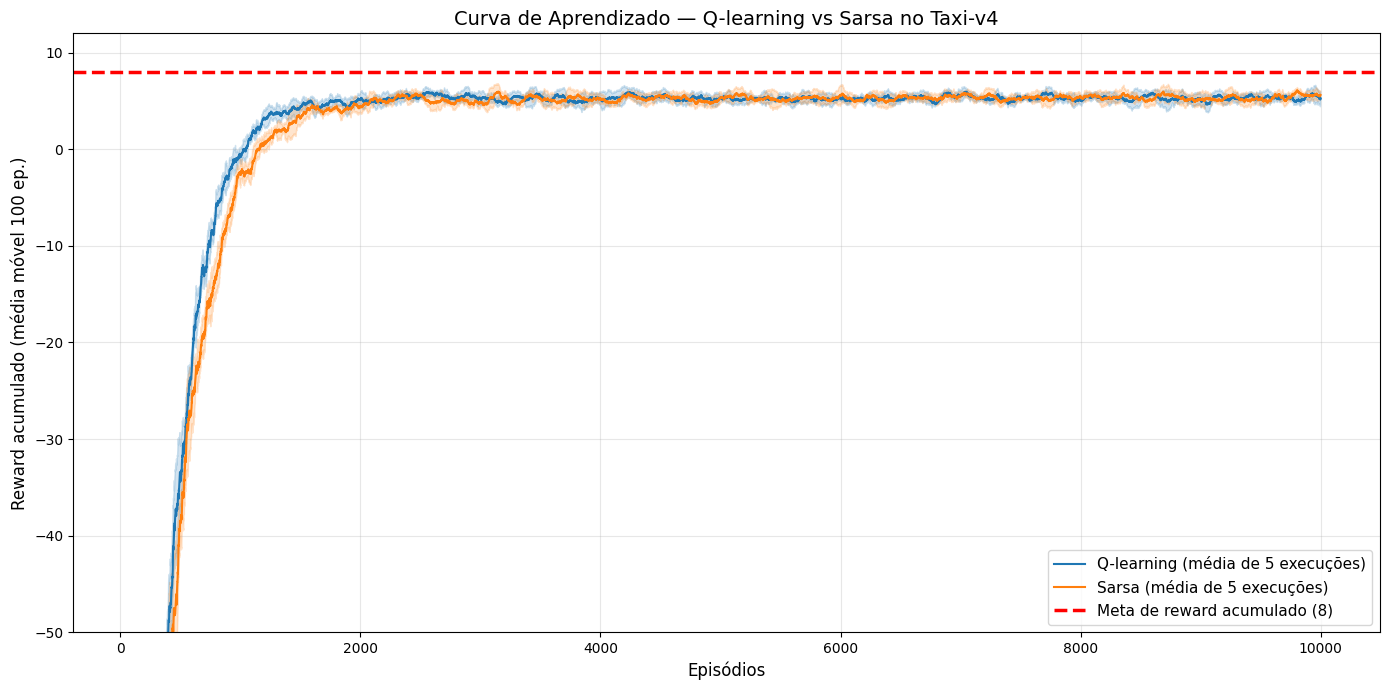

Q-learning | reward ≥ 0: episódios [np.int64(990), np.int64(1063), np.int64(1023), np.int64(936), np.int64(992)] | média 1001
Sarsa | reward ≥ 0: episódios [np.int64(1150), np.int64(1168), np.int64(1098), np.int64(1163), np.int64(1128)] | média 1141
Q-learning | reward ≥ 4: episódios [np.int64(1188), np.int64(1282), np.int64(1186), np.int64(1260), np.int64(1478)] | média 1279
Sarsa | reward ≥ 4: episódios [np.int64(1552), np.int64(1474), np.int64(1399), np.int64(1454), np.int64(1522)] | média 1480


In [27]:
WINDOW = 100

def moving_average(x, window=WINDOW):
    return np.convolve(x, np.ones(window) / window, mode='valid')

def curva_media(rewards_runs):
    curvas = np.array([moving_average(np.array(r)) for r in rewards_runs])
    return curvas.mean(axis=0), curvas.std(axis=0)

x = np.arange(WINDOW, EPISODES + 1)

plt.figure(figsize=(14, 7))
for nome, rewards, cor in [('Q-learning', ql_rewards, 'tab:blue'), 
                           ('Sarsa', sarsa_rewards, 'tab:orange')]:
    media, desvio = curva_media(rewards)
    plt.plot(x, media, color=cor, linewidth=1.5, label=f'{nome} (média de 5 execuções)')
    plt.fill_between(x, media - desvio, media + desvio, color=cor, alpha=0.2)

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.ylim(-50, 12)
plt.xlabel('Episódios', fontsize=12)
plt.ylabel(f'Reward acumulado (média móvel {WINDOW} ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-learning vs Sarsa no Taxi-v4', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_comparacao_curvas.jpg', dpi=120)
plt.show()

def primeiro_episodio(rewards, limiar):
    sm = moving_average(np.array(rewards))
    acima = np.where(sm >= limiar)[0]
    return acima[0] + WINDOW if len(acima) > 0 else None

for limiar in [0, 4]:
    for nome, rewards in [('Q-learning', ql_rewards), ('Sarsa', sarsa_rewards)]:
        eps = [primeiro_episodio(r, limiar) for r in rewards]
        print(f"{nome} | reward ≥ {limiar}: episódios {eps} | média {np.mean(eps):.0f}")

#### Discussão - Q-learning vs Sarsa

**Velocidade de aprendizado**

Para medir qual algoritmo aprende mais rápido, verificamos em que episódio a média móvel do reward (janela de 100 episódios) passou de dois valores: 0 (o agente começa a ganhar mais do que perde) e 4 (o agente já está perto do seu nível final no treino).

| Algoritmo | Reward ≥ 0 | Reward ≥ 4 |
|---|---|---|
| Q-learning | 1001 | 1279 |
| Sarsa | 1141 | 1480 |

O Q-learning aprendeu mais rápido. Ele chegou a reward positivo 140 episódios antes do Sarsa e chegou a 4 200 episódios antes. A diferença foi consistente: todas as cinco execuções do Q-learning chegaram a reward 0 antes de qualquer execução do Sarsa.

**Resultado final**

| Algoritmo | Timesteps (média) | Desvio padrão | Reward médio | Penalidades |
|---|---|---|---|---|
| Q-learning | 12,96 | 2,75 | 8,04 | 0 |
| Sarsa | 12,96 | 2,68 | 8,04 | 0 |

**Por que o Q-learning aprende mais rápido?**

Como cada algoritmo atualiza a Q-table?:
- O **Q-learning** sempre usa o valor da melhor ação do próximo estado. Assim, quando o agente descobre um bom caminho, essa informação se espalha rápido pela Q-table, mesmo que ele esteja explorando.
- O **Sarsa** usa o valor da ação que o agente realmente vai fazer, inclusive as aleatórias. No começo do treino, quando há muitas ações aleatórias, isso também inclue ações mais pessimistas e o aprendizado um pouco mais lento.

**Por que o resultado final é igual?**

A vantagem do Sarsa é aprender caminhos mais seguros quando errar é muito caro, como em um ambiente em que uma ação aleatória faz o agente "cair de um penhasco". No Taxi, o pior erro custa só -10 e, depois do início, o agente explora pouco (5% das ações). Por isso, os dois acabam aprendendo o mesmo caminho.

**Conclusão:** no Taxi determinístico, o Q-learning é um pouco mais eficiente no aprendizado, mas os dois algoritmos têm o mesmo desempenho final.